## Cat vs Dog Image Classification Using Deep Learning

## Project Objective

## The objective of this project is to develop an image classification model that can automatically classify images into two categories: Cat and Dog.

## In this project, three pre-trained deep learning models — VGG16, ResNet50, and EfficientNetB0 — were implemented using transfer learning. Their performance was evaluated and compared based on validation accuracy and loss. The best-performing model was then selected for final prediction.

In [1]:
import zipfile

zip_path = "Cats-Dogs-2.zip"      # Your zip file name
extract_path = "dataset"            # Folder to extract into

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [3]:
dataset_path = "dataset" 

print(os.listdir(dataset_path))

['MSR-LA - 3467.docx', 'PetImages', 'readme[1].txt']


In [4]:
petimages_path = "dataset/PetImages"

print(os.listdir(petimages_path))

['Cat', 'Dog']


In [5]:
## Counting the images

import os

cat_path = "dataset/PetImages/Cat"
dog_path = "dataset/PetImages/Dog"

cat_count = len(os.listdir(cat_path))
dog_count = len(os.listdir(dog_path))

print("Number of Cat Images :", cat_count)
print("Number of Dog Images :", dog_count)

Number of Cat Images : 12501
Number of Dog Images : 12501


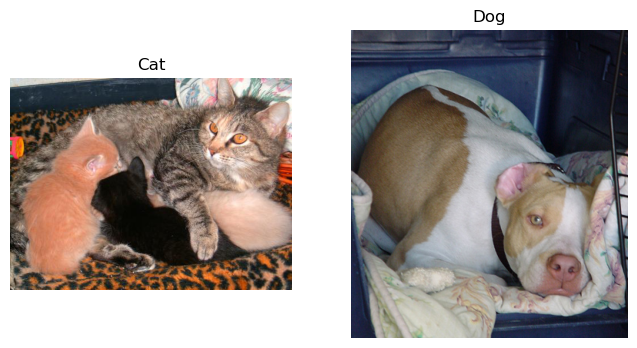

In [6]:
## Visualize Sample Images
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

cat_path = "dataset/PetImages/Cat"
dog_path = "dataset/PetImages/Dog"

# Get random image names
cat_image = random.choice(os.listdir(cat_path))
dog_image = random.choice(os.listdir(dog_path))

# Open images
cat = Image.open(os.path.join(cat_path, cat_image))
dog = Image.open(os.path.join(dog_path, dog_image))

# Display images
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(cat)
plt.title("Cat")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(dog)
plt.title("Dog")
plt.axis("off")

plt.show()

In [7]:
sample_image = Image.open(os.path.join(cat_path, os.listdir(cat_path)[0]))

print("Image Size:", sample_image.size)
print("Image Mode:", sample_image.mode)

Image Size: (500, 375)
Image Mode: RGB


Original Size : (500, 375)
Resized Size  : (224, 224)


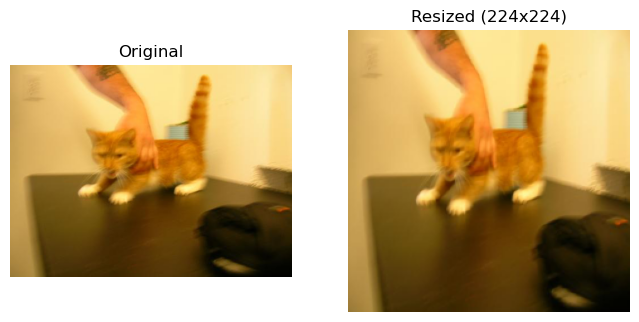

In [8]:
from PIL import Image
import os
import matplotlib.pyplot as plt

sample_image = Image.open(os.path.join(cat_path, os.listdir(cat_path)[0]))

# Resize image
resized_image = sample_image.resize((224, 224))

print("Original Size :", sample_image.size)
print("Resized Size  :", resized_image.size)

# Display both images
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(sample_image)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(resized_image)
plt.title("Resized (224x224)")
plt.axis("off")

plt.show()

In [9]:
from PIL import Image
import os

cat_path = "dataset/PetImages/Cat"
dog_path = "dataset/PetImages/Dog"

corrupted = []

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        # Skip non-image files
        if not file.lower().endswith(".jpg"):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)
            img.verify()
        except Exception:
            corrupted.append(path)

print("Number of Corrupted Images:", len(corrupted))

C:\ProgramData\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Number of Corrupted Images: 2


In [10]:
print("Corrupted Files:")

for file in corrupted:
    print(file)

Corrupted Files:
dataset/PetImages/Cat\666.jpg
dataset/PetImages/Dog\11702.jpg


In [11]:
from PIL import Image

Image.open(corrupted[0])

UnidentifiedImageError: cannot identify image file 'dataset/PetImages/Cat\\666.jpg'

In [12]:
for file in corrupted:
    if file.lower().endswith(".jpg"):
        os.remove(file)

In [13]:
## Rerunning the code to confirm zero corrupted file
from PIL import Image
import os

corrupted = []

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):
        if not file.lower().endswith(".jpg"):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)
            img.verify()
        except Exception:
            corrupted.append(path)

print("Number of Corrupted Images:", len(corrupted))

Number of Corrupted Images: 0


In [14]:
import tensorflow as tf

In [15]:
import tensorflow as tf

print(tf.__version__)

2.20.0


In [16]:
import tensorflow as tf

train_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset/PetImages",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset/PetImages",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.


In [17]:
class_names = train_dataset.class_names

print(class_names)

['Cat', 'Dog']


In [18]:
for images, labels in train_dataset.take(1):
    print("Images Shape:", images.shape)
    print("Labels Shape:", labels.shape)

Images Shape: (32, 224, 224, 3)
Labels Shape: (32,)


In [19]:
for images, labels in train_dataset.take(1):
    print(labels)

tf.Tensor([1 1 1 1 1 1 0 0 0 0 1 1 0 1 0 0 1 0 0 1 0 0 0 1 0 1 0 1 1 1 0 0], shape=(32,), dtype=int32)


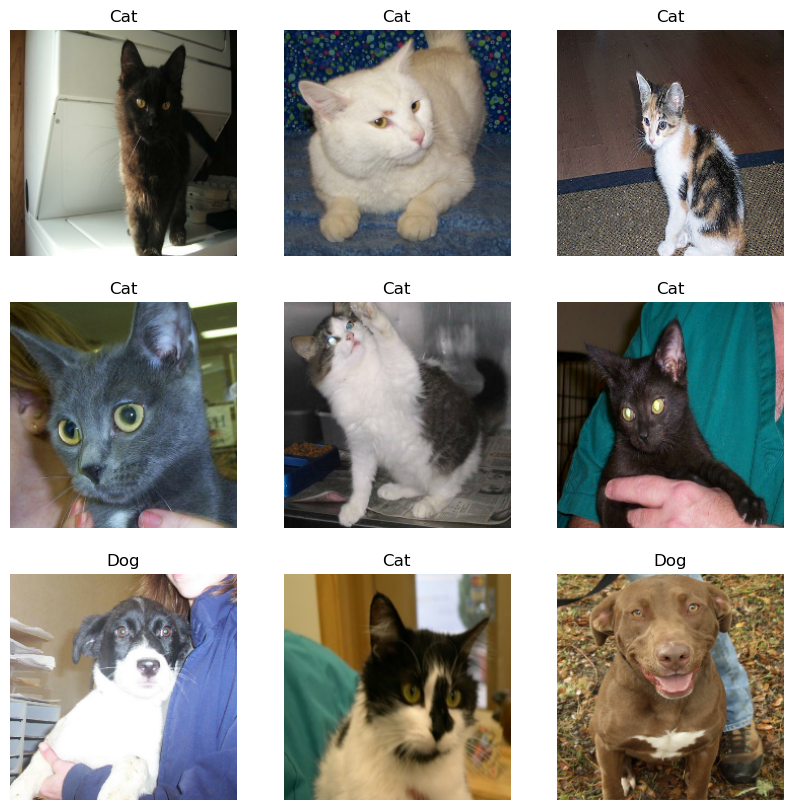

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.show()

In [21]:
## Checking the pixel value

for images, labels in train_dataset.take(1):
    print("Minimum pixel value:", images.numpy().min())
    print("Maximum pixel value:", images.numpy().max())

Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)

validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

## Model 1-- VGG16

In [23]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D

In [24]:
## Load the pretrained model VGG16

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

In [25]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
base_model.trainable = False

In [27]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [28]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D

# Add our own classification layers
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dropout(0.5)(x)

output = Dense(1, activation="sigmoid")(x)

# Create the final model
vgg16_model = Model(
    inputs=base_model.input,
    outputs=output
)

vgg16_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 56, 56, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 28, 28, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 28, 28, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 14, 14, 512)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 7, 7, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,3

 Total params: 14,846,273 (56.63 MB)

 Trainable params: 131,585 (514.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [29]:
vgg16_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [30]:
import os

bad_images = []

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)

            # Check number of channels
            if img.mode not in ["L", "RGB", "RGBA"]:
                bad_images.append((path, img.mode, img.size))

        except Exception as e:
            bad_images.append((path, "Cannot open", str(e)))

print("Number of problematic images:", len(bad_images))

for item in bad_images:
    print(item)

C:\ProgramData\anaconda3\Lib\site-packages\PIL\TiffImagePlugin.py:949: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Number of problematic images: 60
('dataset/PetImages/Cat\\10125.jpg', 'P', (259, 346))
('dataset/PetImages/Cat\\10501.jpg', 'P', (400, 299))
('dataset/PetImages/Cat\\10820.jpg', 'P', (288, 282))
('dataset/PetImages/Cat\\11095.jpg', 'P', (173, 219))
('dataset/PetImages/Cat\\11210.jpg', 'P', (328, 485))
('dataset/PetImages/Cat\\11565.jpg', 'P', (178, 160))
('dataset/PetImages/Cat\\11874.jpg', 'P', (280, 180))
('dataset/PetImages/Cat\\11935.jpg', 'P', (220, 202))
('dataset/PetImages/Cat\\12080.jpg', 'P', (235, 198))
('dataset/PetImages/Cat\\140.jpg', 'P', (253, 265))
('dataset/PetImages/Cat\\2663.jpg', 'P', (194, 83))
('dataset/PetImages/Cat\\3300.jpg', 'P', (250, 228))
('dataset/PetImages/Cat\\3491.jpg', 'P', (259, 346))
('dataset/PetImages/Cat\\4833.jpg', 'P', (85, 95))
('dataset/PetImages/Cat\\5370.jpg', 'P', (275, 226))
('dataset/PetImages/Cat\\5553.jpg', 'P', (288, 279))
('dataset/PetImages/Cat\\6435.jpg', 'P', (274, 170))
('dataset/PetImages/Cat\\660.jpg', 'P', (259, 346))
('dataset

In [31]:
from collections import Counter

print("Image modes found:")

mode_counts = Counter()

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)
            mode_counts[img.mode] += 1

        except Exception:
            mode_counts["Cannot open"] += 1

print(mode_counts)

Image modes found:
Counter({'RGB': 24931, 'P': 57, 'L': 5, 'CMYK': 3, 'RGBA': 2})


In [32]:
from PIL import Image
import os

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)

            if img.mode != "RGB":
                img = img.convert("RGB")
                img.save(path)

        except Exception as e:
            print("Could not convert:", path)
            print("Error:", e)

print("All non-RGB images converted to RGB!")

All non-RGB images converted to RGB!


In [33]:
from collections import Counter

mode_counts = Counter()

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        try:
            img = Image.open(path)
            mode_counts[img.mode] += 1

        except Exception:
            mode_counts["Cannot open"] += 1

print(mode_counts)

Counter({'RGB': 24998})


In [34]:
import tensorflow as tf

train_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset/PetImages",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset/PetImages",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Found 24998 files belonging to 2 classes.
Using 4999 files for validation.


In [35]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

In [36]:
import os
import tensorflow as tf

tensorflow_bad = []

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        try:
            image_bytes = tf.io.read_file(path)
            image = tf.io.decode_image(
                image_bytes,
                channels=0,
                expand_animations=False
            )

            channels = image.shape[-1]

            if channels not in [1, 3, 4]:
                tensorflow_bad.append((path, channels))

        except Exception as e:
            tensorflow_bad.append((path, str(e)))

print("TensorFlow problematic images:", len(tensorflow_bad))

for item in tensorflow_bad:
    print(item)

TensorFlow problematic images: 7
('dataset/PetImages/Cat\\10404.jpg', '{{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, PNG, GIF, BMP, WebP required. [Op:DecodeImage] name: ')
('dataset/PetImages/Cat\\4351.jpg', '{{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Input size should match (header_size + row_size * abs_height) but they differ by 2 [Op:DecodeImage] name: ')
('dataset/PetImages/Dog\\11233.jpg', '{{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: ')
('dataset/PetImages/Dog\\11912.jpg', '{{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Number of channels inherent in the image must be 1, 3 or 4, was 2 [Op:DecodeImage] name: ')
('dataset/PetImages/Dog\\2317.jpg', '{{function_node __

In [37]:
problem_files = [
    r"dataset/PetImages/Cat\10404.jpg",
    r"dataset/PetImages/Cat\4351.jpg",
    r"dataset/PetImages/Dog\11233.jpg",
    r"dataset/PetImages/Dog\11912.jpg",
    r"dataset/PetImages/Dog\2317.jpg",
    r"dataset/PetImages/Dog\2494.jpg",
    r"dataset/PetImages/Dog\9500.jpg"
]

for file in problem_files:
    if os.path.exists(file):
        os.remove(file)
        print("Removed:", file)
    else:
        print("File not found:", file)

print("Finished!")

Removed: dataset/PetImages/Cat\10404.jpg
Removed: dataset/PetImages/Cat\4351.jpg
Removed: dataset/PetImages/Dog\11233.jpg
Removed: dataset/PetImages/Dog\11912.jpg
Removed: dataset/PetImages/Dog\2317.jpg
Removed: dataset/PetImages/Dog\2494.jpg
Removed: dataset/PetImages/Dog\9500.jpg
Finished!


In [38]:
import os
import tensorflow as tf

tensorflow_bad = []

for folder in [cat_path, dog_path]:
    for file in os.listdir(folder):

        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, file)

        try:
            image_bytes = tf.io.read_file(path)
            image = tf.io.decode_image(
                image_bytes,
                channels=0,
                expand_animations=False
            )

            channels = image.shape[-1]

            if channels not in [1, 3, 4]:
                tensorflow_bad.append((path, channels))

        except Exception as e:
            tensorflow_bad.append((path, str(e)))

print("TensorFlow problematic images:", len(tensorflow_bad))

for item in tensorflow_bad:
    print(item)

TensorFlow problematic images: 0


In [39]:
import tensorflow as tf

train_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset/PetImages",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    "dataset/PetImages",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224, 224),
    batch_size=32
)

Found 24991 files belonging to 2 classes.
Using 19993 files for training.
Found 24991 files belonging to 2 classes.
Using 4998 files for validation.


In [40]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

In [41]:
for images, labels in train_dataset:
    pass

print("Training dataset checked successfully!")

Training dataset checked successfully!


In [43]:
## Train the VGG16 model

history_vgg16 = vgg16_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3
)

Epoch 1/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 5612s 9s/step - accuracy: 0.9573 - loss: 0.1236 - val_accuracy: 0.9710 - val_loss: 0.0708
Epoch 2/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 5465s 9s/step - accuracy: 0.9727 - loss: 0.0726 - val_accuracy: 0.9706 - val_loss: 0.0737
Epoch 3/3
625/625 ━━━━━━━━━━━━━━━━━━━━ 14436s 23s/step - accuracy: 0.9741 - loss: 0.0674 - val_accuracy: 0.9724 - val_loss: 0.0689


In [44]:
print(tf.config.list_physical_devices('GPU'))

[]


In [45]:
vgg16_model.save("vgg16_cat_dog.keras")

In [ ]:
## RELOAD THE MODEL
## from tensorflow.keras.models import load_model

## vgg16_model = load_model("vgg16_cat_dog.keras")

## MODEL2 RESNET50

In [46]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D

In [47]:
base_resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 42s 0us/step 


In [48]:
base_resnet.trainable = False

In [49]:
x = base_resnet.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dropout(0.5)(x)

output = Dense(1, activation="sigmoid")(x)

resnet50_model = Model(
    inputs=base_resnet.input,
    outputs=output
)

In [50]:
resnet50_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_pad (ZeroPadding2D)     │ (None, 230, 230, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_conv (Conv2D)           │ (None, 112, 112, 64)      │           9,472 │ conv1_pad[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_bn (BatchNormalization) │ (None, 112, 112, 64)      │             256 │ conv1_conv[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_relu (Activation)       │ (None, 112, 112, 64)      │               0 │ conv1_bn[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1_pad (ZeroPadding2D)     │ (None, 114, 114, 64)      │               0 │ conv1_relu[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1_pool (MaxPooling2D)     │ (None, 56, 56, 64)        │               0 │ pool1_pad[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_conv (Conv2D)  │ (None, 56, 56, 64)        │           4,160 │ pool1_pool[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_bn             │ (None, 56, 56, 64)        │             256 │ conv2_block1_1_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_1_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_conv (Conv2D)  │ (None, 56, 56, 64)        │          36,928 │ conv2_block1_1_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_bn             │ (None, 56, 56, 64)        │             256 │ conv2_block1_2_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_2_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_conv (Conv2D)  │ (None, 56, 56, 256)       │          16,640 │ pool1_pool[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_3_conv (Conv2D)  │ (None, 56, 56, 256)       │          16,640 │ conv2_block1_2_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [51]:
small_train_dataset = train_dataset.take(157)

In [52]:
small_validation_dataset = validation_dataset.take(32)

In [ ]:
## 157*32 Training → 5,024 images
## 32* 32 (batch size)validation → 1,024 images

In [54]:
resnet50_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [55]:
history_resnet = resnet50_model.fit(
    small_train_dataset,
    validation_data=small_validation_dataset,
    epochs=1
)

157/157 ━━━━━━━━━━━━━━━━━━━━ 443s 3s/step - accuracy: 0.9494 - loss: 0.1315 - val_accuracy: 0.9795 - val_loss: 0.0575


In [56]:
resnet50_model.save("resnet50_cat_dog.keras")

## Model 3--EfficientNetB0

In [57]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D

In [58]:
base_efficientnet = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 11s 1us/step 


In [59]:
base_efficientnet.trainable = False

In [60]:
x = base_efficientnet.output

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation="relu")(x)

x = Dropout(0.5)(x)

output = Dense(1, activation="sigmoid")(x)

efficientnet_model = Model(
    inputs=base_efficientnet.input,
    outputs=output
)

In [61]:
efficientnet_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling (Rescaling)         │ (None, 224, 224, 3)       │               0 │ input_layer_2[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ normalization (Normalization) │ (None, 224, 224, 3)       │               7 │ rescaling[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ rescaling_1 (Rescaling)       │ (None, 224, 224, 3)       │               0 │ normalization[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv_pad (ZeroPadding2D) │ (None, 225, 225, 3)       │               0 │ rescaling_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_conv (Conv2D)            │ (None, 112, 112, 32)      │             864 │ stem_conv_pad[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_bn (BatchNormalization)  │ (None, 112, 112, 32)      │             128 │ stem_conv[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stem_activation (Activation)  │ (None, 112, 112, 32)      │               0 │ stem_bn[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_dwconv                │ (None, 112, 112, 32)      │             288 │ stem_activation[0][0]      │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_bn                    │ (None, 112, 112, 32)      │             128 │ block1a_dwconv[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_activation            │ (None, 112, 112, 32)      │               0 │ block1a_bn[0][0]           │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_squeeze            │ (None, 32)                │               0 │ block1a_activation[0][0]   │
│ (GlobalAveragePooling2D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reshape (Reshape)  │ (None, 1, 1, 32)          │               0 │ block1a_se_squeeze[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_reduce (Conv2D)    │ (None, 1, 1, 8)           │             264 │ block1a_se_reshape[0][0]   │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block1a_se_expand (Conv2D)    │ (None, 1, 1, 32)          │             288 │ block1a_se_reduce[0][0]    │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [62]:
efficientnet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [63]:
history_efficientnet = efficientnet_model.fit(
    small_train_dataset,
    validation_data=small_validation_dataset,
    epochs=1
)

157/157 ━━━━━━━━━━━━━━━━━━━━ 160s 911ms/step - accuracy: 0.9825 - loss: 0.0491 - val_accuracy: 0.9893 - val_loss: 0.0426


In [64]:
efficientnet_model.save("efficientnetb0_cat_dog.keras")

In [65]:
vgg16_result = vgg16_model.evaluate(
    small_validation_dataset,
    verbose=1
)

print("VGG16 Loss:", vgg16_result[0])
print("VGG16 Accuracy:", vgg16_result[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 228s 7s/step - accuracy: 0.9746 - loss: 0.0811
VGG16 Loss: 0.08114030212163925
VGG16 Accuracy: 0.974609375


In [66]:
resnet50_result = resnet50_model.evaluate(
    small_validation_dataset,
    verbose=1
)

print("ResNet50 Loss:", resnet50_result[0])
print("ResNet50 Accuracy:", resnet50_result[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.9814 - loss: 0.0603 
ResNet50 Loss: 0.060291409492492676
ResNet50 Accuracy: 0.9814453125


In [67]:
efficientnet_result = efficientnet_model.evaluate(
    small_validation_dataset,
    verbose=1
)

print("EfficientNetB0 Loss:", efficientnet_result[0])
print("EfficientNetB0 Accuracy:", efficientnet_result[1])

32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 710ms/step - accuracy: 0.9902 - loss: 0.0421
EfficientNetB0 Loss: 0.04209526628255844
EfficientNetB0 Accuracy: 0.990234375


In [68]:
import numpy as np

y_true = []
y_pred = []

for images, labels in small_validation_dataset:
    predictions = efficientnet_model.predict(images, verbose=0)
    
    y_true.extend(labels.numpy())
    y_pred.extend((predictions > 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions completed!")

Predictions completed!


## Classification report

In [69]:
## Classification report
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Cat", "Dog"]
))


              precision    recall  f1-score   support

         Cat       0.99      0.99      0.99       497
         Dog       0.99      0.99      0.99       527

    accuracy                           0.99      1024
   macro avg       0.99      0.99      0.99      1024
weighted avg       0.99      0.99      0.99      1024



## Confusion matrix

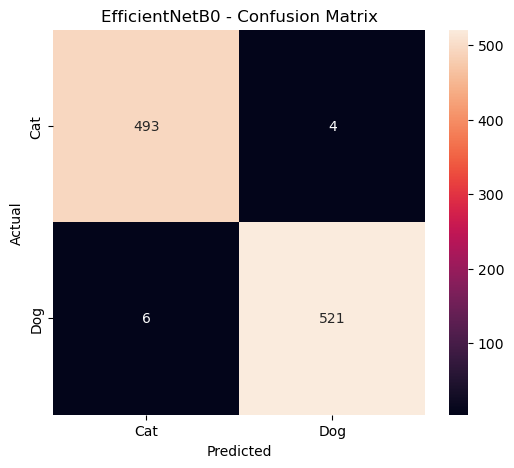

In [70]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Cat", "Dog"],
    yticklabels=["Cat", "Dog"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("EfficientNetB0 - Confusion Matrix")
plt.show()

In [71]:
print(confusion_matrix(y_true, y_pred))

[[493   4]
 [  6 521]]


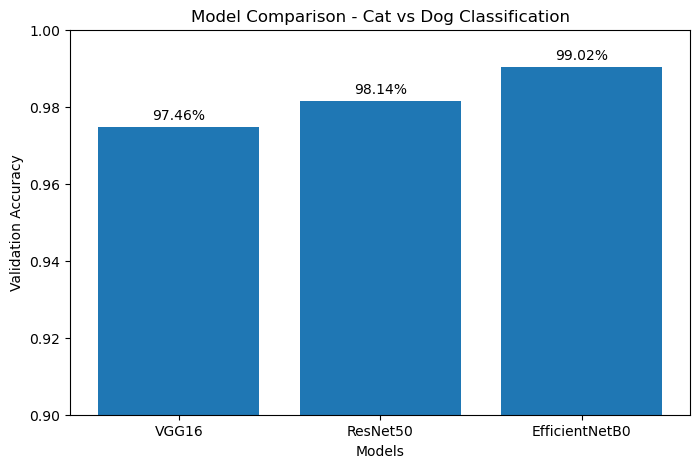

In [72]:
import matplotlib.pyplot as plt

models = ["VGG16", "ResNet50", "EfficientNetB0"]
accuracies = [0.974609375, 0.9814453125, 0.990234375]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)

plt.xlabel("Models")
plt.ylabel("Validation Accuracy")
plt.title("Model Comparison - Cat vs Dog Classification")
plt.ylim(0.90, 1.00)

for i, accuracy in enumerate(accuracies):
    plt.text(i, accuracy + 0.002, f"{accuracy*100:.2f}%",
             ha="center")

plt.show()

In [73]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'Cat And Dog Project.ipynb', 'Cats-Dogs-2.zip', 'cat_test.jpg', 'dataset', 'efficientnetb0_cat_dog.keras', 'resnet50_cat_dog.keras', 'vgg16_cat_dog.keras']


In [74]:
from tensorflow.keras.utils import load_img, img_to_array

image = load_img(
    "cat_test.jpg",
    target_size=(224, 224)
)

image_array = img_to_array(image)

print("Image shape:", image_array.shape)

Image shape: (224, 224, 3)


In [75]:
import numpy as np

image_batch = np.expand_dims(image_array, axis=0)

prediction = efficientnet_model.predict(image_batch)

print("Prediction value:", prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Prediction value: 0.00011265238


In [ ]:
0 → Cat 
1 → Dog 

## Prediction: CAT

## "The EfficientNetB0 model predicted the new image as a Cat with approximately 99.99% confidence."

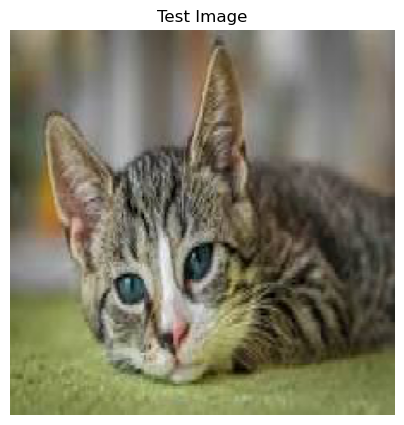

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Test Image")
plt.show()

## Conclusion

## In this project, a deep learning-based Cat vs Dog image classification system was successfully developed using transfer learning.

## Three pre-trained CNN models — VGG16, ResNet50, and EfficientNetB0 — were trained and evaluated. The models were compared using the same validation dataset.

## Model	Validation Accuracy
## VGG16	97.46%
## ResNet50	98.14%
## EfficientNetB0	99.02%

 Among the three models, EfficientNetB0 achieved the highest validation accuracy of 99.02% and the lowest validation loss. It also required fewer parameters and was faster during evaluation compared with VGG16 and ResNet50.

 Overall, this project demonstrates how transfer learning and pre-trained CNN architectures can be effectively used to build accurate image classification models even when training computational resources are limited.

 ## “I compared VGG16, ResNet50, and EfficientNetB0 using a common validation dataset. EfficientNetB0 performed best with 99.02% validation accuracy, so I selected it as the final model.”